In [17]:
import openseespy.opensees as ops
import numpy as np
import matplotlib.pyplot as plt

In [18]:
# ============================================================
# 导线与档距参数
# ============================================================

L = 300.0          # 档距，m
H1 = 30.0          # 左挂点高度，m
H2 = 30.0          # 右挂点高度，m

A = 4.0e-4         # 导线截面面积，m2
E = 7.0e10         # 弹性模量，Pa

n_seg = 60         # 导线离散段数
n_node = n_seg + 1

# ============================================================
# 荷载参数
# ============================================================

# 推荐直接使用单位长度重力，单位 N/m
# 例如某导线自重为 15 N/m
q_g = 15.0

# ============================================================
# 目标弧垂
# ============================================================

sag_target = 8.0   # 目标弧垂，m

# ============================================================
# 初始应力搜索范围
# ============================================================

sigma_low = 1.0e4       # Pa，较小应力，弧垂大
sigma_high = 300.0e6    # Pa，较大应力，弧垂小

tol_sag = 1.0e-3        # 弧垂容许误差，m
max_iter = 40           # 最大外层二分迭代次数

In [19]:
def calculate_sag_relative_to_chord(final_coords, H1, H2, L):
    """
    计算相对于两端挂点连线的最大弧垂。

    final_coords:
        shape = (n_node, 3)
        每行是一个节点最终坐标 [x, y, z]

    弧垂定义：
        sag_i = chord_z(x_i) - z_i

    其中 chord_z 是两端挂点连线在 x_i 处的高度。
    """

    max_sag = -1.0e30

    for p in final_coords:
        x = p[0]
        z = p[2]

        chord_z = H1 + (H2 - H1) * x / L
        sag_i = chord_z - z

        if sag_i > max_sag:
            max_sag = sag_i

    return max_sag

In [20]:
def run_static_formfinding_with_init_stress(
    init_stress,
    L=300.0,
    H1=30.0,
    H2=30.0,
    A=4.0e-4,
    E=7.0e10,
    q_g=15.0,
    n_seg=60,
    initial_sag=0.2,
    n_steps=100,
    verbose=False,
):
    """
    给定 init_stress，建立导线模型，施加自重，进行静力非线性分析。

    返回：
        sag_final: 最终最大弧垂
        final_coords: 最终节点坐标
        axial_forces: 单元轴力
        ok: 分析是否成功
    """

    ops.wipe()

    # ============================================================
    # 1. 建立三维模型
    # ============================================================

    ops.model("basic", "-ndm", 3, "-ndf", 3)

    n_node = n_seg + 1

    # ============================================================
    # 2. 定义材料
    # ============================================================

    ops.uniaxialMaterial("Elastic", 1, E)

    # InitStressMaterial 中的 init_stress 是初始应力，单位 Pa
    ops.uniaxialMaterial("InitStressMaterial", 2, 1, init_stress)

    # ============================================================
    # 3. 建立节点
    # ============================================================

    for i in range(n_node):
        xi = i / n_seg

        x = L * xi
        y = 0.0

        # 两端挂点连线高度
        z_linear = H1 + (H2 - H1) * xi

        # 初始给一个很小的下挠，不代表目标弧垂
        z = z_linear - 4.0 * initial_sag * xi * (1.0 - xi)

        ops.node(i + 1, x, y, z)

    # ============================================================
    # 4. 边界条件
    # ============================================================

    ops.fix(1, 1, 1, 1)
    ops.fix(n_node, 1, 1, 1)

    # ============================================================
    # 5. 建立 corotTruss 单元
    # ============================================================

    for i in range(n_seg):
        ele_tag = i + 1
        i_node = i + 1
        j_node = i + 2

        ops.element(
            "corotTruss",
            ele_tag,
            i_node,
            j_node,
            A,
            2
        )

    # ============================================================
    # 6. 施加节点等效自重
    # ============================================================

    ops.timeSeries("Linear", 1)
    ops.pattern("Plain", 1, 1)

    dx = L / n_seg

    for i in range(n_node):
        node_tag = i + 1

        if i == 0 or i == n_node - 1:
            trib_length = dx / 2.0
        else:
            trib_length = dx

        weight = q_g * trib_length

        # 全局 Z 方向向下
        ops.load(node_tag, 0.0, 0.0, -weight)

    # ============================================================
    # 7. 静力分析设置
    # ============================================================

    ops.constraints("Plain")
    ops.numberer("RCM")
    ops.system("BandGeneral")

    ops.test("NormDispIncr", 1.0e-8, 50)
    ops.algorithm("Newton")

    # 分 n_steps 步逐渐施加自重
    ops.integrator("LoadControl", 1.0 / n_steps)

    ops.analysis("Static")

    # ============================================================
    # 8. 执行静力分析
    # ============================================================

    ok_total = 0

    for step in range(n_steps):
        ok = ops.analyze(1)

        if ok != 0:
            if verbose:
                print(f"常规 Newton 不收敛，step = {step + 1}，尝试减小荷载步。")

            # 尝试减小荷载步
            ops.integrator("LoadControl", 1.0 / n_steps / 10.0)
            ok = ops.analyze(10)

            # 恢复原荷载步
            ops.integrator("LoadControl", 1.0 / n_steps)

            if ok != 0:
                ok_total = ok

                if verbose:
                    print(f"静力分析失败，init_stress = {init_stress:.6e}")

                break

    analysis_success = (ok_total == 0)

    # ============================================================
    # 9. 提取最终节点坐标
    # ============================================================

    final_coords = []

    for node in range(1, n_node + 1):
        coord = np.array(ops.nodeCoord(node), dtype=float)
        disp = np.array(ops.nodeDisp(node), dtype=float)
        final_coord = coord + disp
        final_coords.append(final_coord)

    final_coords = np.array(final_coords)

    # ============================================================
    # 10. 计算最终弧垂
    # ============================================================

    sag_final = calculate_sag_relative_to_chord(final_coords, H1, H2, L)

    # ============================================================
    # 11. 提取单元轴力
    # ============================================================

    axial_forces = []

    for ele in range(1, n_seg + 1):
        try:
            response = ops.eleResponse(ele, "axialForce")

            if isinstance(response, (list, tuple)) and len(response) > 0:
                axial_forces.append(response[0])
            else:
                axial_forces.append(np.nan)

        except Exception:
            axial_forces.append(np.nan)

    axial_forces = np.array(axial_forces, dtype=float)

    return sag_final, final_coords, axial_forces, analysis_success

In [21]:
sigma_test = 50.0e6  # 50 MPa

sag_test, coords_test, axial_test, success_test = run_static_formfinding_with_init_stress(
    init_stress=sigma_test,
    L=L,
    H1=H1,
    H2=H2,
    A=A,
    E=E,
    q_g=q_g,
    n_seg=n_seg,
    initial_sag=0.2,
    n_steps=100,
    verbose=True,
)

print("分析是否成功:", success_test)
print("测试初始应力:", sigma_test, "Pa")
print("最终弧垂:", sag_test, "m")
print("等效初始张力:", sigma_test * A, "N")

分析是否成功: True
测试初始应力: 50000000.0 Pa
最终弧垂: 4.548041323862719 m
等效初始张力: 20000.0 N


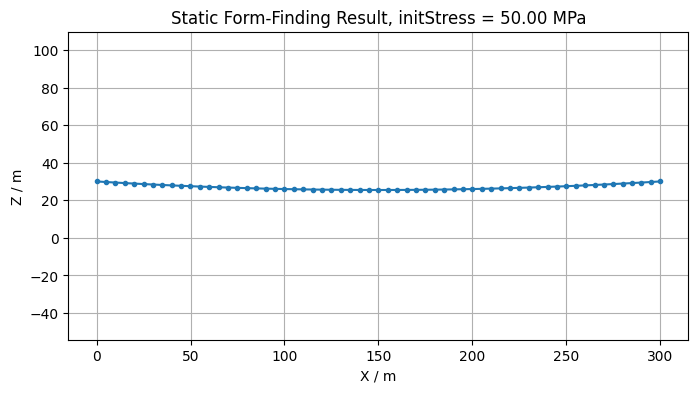

In [22]:
plt.figure(figsize=(8, 4))

plt.plot(coords_test[:, 0], coords_test[:, 2], marker="o", markersize=3)

plt.xlabel("X / m")
plt.ylabel("Z / m")
plt.title(f"Static Form-Finding Result, initStress = {sigma_test / 1e6:.2f} MPa")
plt.grid(True)
plt.axis("equal")
plt.show()

In [23]:
def formfind_by_target_sag_static(
    sag_target,
    sigma_low,
    sigma_high,
    tol_sag=1.0e-3,
    max_iter=40,
    **kwargs
):
    """
    使用二分法迭代 init_stress，使静力平衡后的最大弧垂接近 sag_target。
    """

    # ============================================================
    # 1. 先检查上下限是否包络目标弧垂
    # ============================================================

    sag_low, coords_low, axial_low, success_low = run_static_formfinding_with_init_stress(
        init_stress=sigma_low,
        **kwargs
    )

    sag_high, coords_high, axial_high, success_high = run_static_formfinding_with_init_stress(
        init_stress=sigma_high,
        **kwargs
    )

    print("初始区间检查：")
    print(f"sigma_low  = {sigma_low:.6e} Pa, sag_low  = {sag_low:.6f} m, success = {success_low}")
    print(f"sigma_high = {sigma_high:.6e} Pa, sag_high = {sag_high:.6f} m, success = {success_high}")
    print(f"sag_target = {sag_target:.6f} m")
    print()

    if not success_low:
        raise RuntimeError("sigma_low 对应的静力分析失败，请调整 sigma_low 或分析参数。")

    if not success_high:
        raise RuntimeError("sigma_high 对应的静力分析失败，请调整 sigma_high 或分析参数。")

    # 正常情况下：
    # sigma_low 较小，弧垂较大；
    # sigma_high 较大，弧垂较小。
    if not (sag_low >= sag_target >= sag_high):
        raise ValueError(
            "当前 sigma_low 和 sigma_high 没有包络目标弧垂。\n"
            "通常需要满足：sag_low >= sag_target >= sag_high。\n"
            "如果 sag_low < sag_target，说明 sigma_low 仍然太大；\n"
            "如果 sag_high > sag_target，说明 sigma_high 仍然太小。"
        )

    # ============================================================
    # 2. 开始二分
    # ============================================================

    history = []
    best_result = None

    print("二分迭代过程：")
    print(
        f"{'iter':>6s} | "
        f"{'initStress/MPa':>16s} | "
        f"{'sag/m':>12s} | "
        f"{'error/m':>12s} | "
        f"{'success':>8s}"
    )
    print("-" * 68)

    for it in range(1, max_iter + 1):
        sigma_mid = 0.5 * (sigma_low + sigma_high)

        sag_mid, coords_mid, axial_mid, success_mid = run_static_formfinding_with_init_stress(
            init_stress=sigma_mid,
            **kwargs
        )

        error = sag_mid - sag_target

        history.append({
            "iteration": it,
            "init_stress": sigma_mid,
            "sag": sag_mid,
            "error": error,
            "success": success_mid
        })

        print(
            f"{it:6d} | "
            f"{sigma_mid / 1e6:16.6f} | "
            f"{sag_mid:12.6f} | "
            f"{error:12.6e} | "
            f"{str(success_mid):>8s}"
        )

        if not success_mid:
            raise RuntimeError(
                f"二分过程中静力分析失败，iteration = {it}, init_stress = {sigma_mid:.6e} Pa"
            )

        best_result = {
            "init_stress": sigma_mid,
            "sag": sag_mid,
            "error": error,
            "final_coords": coords_mid,
            "axial_forces": axial_mid,
            "success": success_mid,
            "iteration": it,
            "history": history,
        }

        if abs(error) < tol_sag:
            print("\n满足弧垂误差要求，二分结束。")
            return best_result

        if sag_mid > sag_target:
            # 弧垂偏大，说明张力偏小，需要增大 init_stress
            sigma_low = sigma_mid
        else:
            # 弧垂偏小，说明张力偏大，需要减小 init_stress
            sigma_high = sigma_mid

    print("\n达到最大迭代次数，返回当前结果。")
    return best_result

In [24]:
result = formfind_by_target_sag_static(
    sag_target=sag_target,
    sigma_low=sigma_low,
    sigma_high=sigma_high,
    tol_sag=tol_sag,
    max_iter=max_iter,
    L=L,
    H1=H1,
    H2=H2,
    A=A,
    E=E,
    q_g=q_g,
    n_seg=n_seg,
    initial_sag=0.2,
    n_steps=100,
    verbose=False,
)

初始区间检查：
sigma_low  = 1.000000e+04 Pa, sag_low  = 5.885986 m, success = True
sigma_high = 3.000000e+08 Pa, sag_high = 1.388186 m, success = True
sag_target = 8.000000 m



ValueError: 当前 sigma_low 和 sigma_high 没有包络目标弧垂。
通常需要满足：sag_low >= sag_target >= sag_high。
如果 sag_low < sag_target，说明 sigma_low 仍然太大；
如果 sag_high > sag_target，说明 sigma_high 仍然太小。

In [ ]:
print("\n================ 最终找形结果 ================")
print(f"目标弧垂 sag_target       = {sag_target:.6f} m")
print(f"最终弧垂 sag_final        = {result['sag']:.6f} m")
print(f"弧垂误差 error            = {result['error']:.6e} m")
print(f"迭代得到 initStress       = {result['init_stress']:.6e} Pa")
print(f"迭代得到 initStress       = {result['init_stress'] / 1e6:.6f} MPa")
print(f"等效初始张力 T0           = {result['init_stress'] * A:.6f} N")
print(f"静力分析是否成功          = {result['success']}")
print(f"外层二分迭代次数          = {result['iteration']}")

axial = result["axial_forces"]

print("\n单元轴力统计：")
print(f"N_min = {np.nanmin(axial):.6f} N")
print(f"N_max = {np.nanmax(axial):.6f} N")
print(f"N_avg = {np.nanmean(axial):.6f} N")

In [ ]:
final_coords = result["final_coords"]

plt.figure(figsize=(8, 4))

plt.plot(final_coords[:, 0], final_coords[:, 2], marker="o", markersize=3)

# 挂点连线
x_chord = np.array([0.0, L])
z_chord = np.array([H1, H2])
plt.plot(x_chord, z_chord, linestyle="--")

plt.xlabel("X / m")
plt.ylabel("Z / m")
plt.title(
    f"Final Shape, sag = {result['sag']:.3f} m, "
    f"initStress = {result['init_stress'] / 1e6:.3f} MPa"
)
plt.grid(True)
plt.axis("equal")
plt.show()

In [ ]:
history = result["history"]

iters = [h["iteration"] for h in history]
sags = [h["sag"] for h in history]
errors = [h["error"] for h in history]
stresses = [h["init_stress"] / 1e6 for h in history]

plt.figure(figsize=(7, 4))
plt.plot(iters, sags, marker="o")
plt.axhline(sag_target, linestyle="--")
plt.xlabel("Iteration")
plt.ylabel("Sag / m")
plt.title("Sag Convergence")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(iters, stresses, marker="o")
plt.xlabel("Iteration")
plt.ylabel("initStress / MPa")
plt.title("initStress Iteration")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(iters, errors, marker="o")
plt.axhline(0.0, linestyle="--")
plt.xlabel("Iteration")
plt.ylabel("Sag Error / m")
plt.title("Sag Error Convergence")
plt.grid(True)
plt.show()

In [ ]:
print(f"{'node':>6s} | {'x/m':>12s} | {'y/m':>12s} | {'z/m':>12s}")
print("-" * 52)

for i, p in enumerate(final_coords, start=1):
    print(f"{i:6d} | {p[0]:12.6f} | {p[1]:12.6f} | {p[2]:12.6f}")

In [ ]:
axial = result["axial_forces"]

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(axial) + 1), axial, marker="o", markersize=3)
plt.xlabel("Element Tag")
plt.ylabel("Axial Force / N")
plt.title("Axial Force Distribution")
plt.grid(True)
plt.show()